# Лабораторна робота № 10 — трансферне навчання у TensorFlow / Keras 3

**Варіант 17.** Food-101: `cheese_plate`, `garlic_bread`, `pizza` (індекси 16, 46, 76 у `meta/classes.txt`). Мета — порівняти навчання нової голови EfficientNetB0 із частковим донавчанням бази, обрати checkpoint за validation loss та один раз оцінити його на незалежному test.

Виконувати клітинки послідовно. Джерело даних і незмінний поділ — лабораторна № 9. Мітки: 0 — `cheese_plate`, 1 — `garlic_bread`, 2 — `pizza`. Зображення та великі файли моделі не слід додавати до Git.

## 1. Середовище та шляхи

Потрібні TensorFlow ≥ 2.16, Keras 3, NumPy, Matplotlib, scikit-learn і Pillow. У цьому репозиторії готове ядро `Lab5/.venv/bin/python`. Для завантаження ImageNet-ваг під час першого запуску потрібен інтернет. CPU працює, але навчання може бути тривалим.

In [1]:
import json
import os
import platform
import sys
from collections import Counter, defaultdict
from hashlib import sha256
from pathlib import Path

# Окремий локальний кеш ваг і шрифтів для запуску з кореня або з Lab10.
_cache_root = Path.cwd() / "Lab10" if (Path.cwd() / "Lab10").is_dir() else Path.cwd()
os.environ.setdefault("KERAS_HOME", str(_cache_root / ".keras"))
os.environ.setdefault("MPLCONFIGDIR", str(_cache_root / ".mplcache"))
Path(os.environ["KERAS_HOME"]).mkdir(exist_ok=True)
Path(os.environ["MPLCONFIGDIR"]).mkdir(exist_ok=True)

import matplotlib.pyplot as plt
from IPython.display import Image as NotebookImage, display
import numpy as np
import tensorflow as tf
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
HEAD_EPOCHS = FINE_EPOCHS = 10
BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)
keras.utils.set_random_seed(SEED)

ROOT = Path.cwd().resolve()
if not (ROOT / "Lab9" / "manifest.json").is_file():
    ROOT = ROOT.parent
assert (ROOT / "Lab9" / "manifest.json").is_file(), "Запускайте з кореня репозиторію або з Lab10."
LAB_DIR = ROOT / "Lab10"
DATA_DIR = ROOT / "Lab9" / "data" / "food101_lab9"
MANIFEST_PATH = ROOT / "Lab9" / "manifest.json"
OUT = LAB_DIR / "results"
OUT.mkdir(exist_ok=True)
print("Python", sys.version.split()[0], "TensorFlow", tf.__version__, "Keras", keras.__version__)
print(platform.platform(), tf.config.list_physical_devices())
assert tuple(map(int, tf.__version__.split(".")[:2])) >= (2, 16)
assert int(keras.__version__.split(".")[0]) >= 3

/Users/staslulko/Documents/GitHub/data-mining/Lab5/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Python 3.9.6 TensorFlow 2.16.2 Keras 3.10.0
macOS-14.8.5-x86_64-i386-64bit [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Дані та фіксований поділ

[Food-101, ETH Zürich](https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/) містить фото страв із Foodspotting. [Картка ETH](https://huggingface.co/datasets/ethz/food101/blob/main/README.md) вказує, що права на фото належать авторам; використання поза науковими цілями потребує узгодження. У Lab9 офіційний train розділено за seed 42 на 600 train і 150 validation фото кожного класу; офіційний test має 250 фото кожного класу. Частки від загальних 3000 фото: 60/15/25. Дисбалансу за кількістю немає.

Точні дублікати перевіряємо за SHA-256. Різні знімки того самого об'єкта або серії не можна надійно встановити лише за ID Food-101; це обмеження поділу. Аугментацію застосовуємо **після** поділу тільки до train. Горизонтальне віддзеркалення і поворот на 5% оберту зберігають клас страви.

In [2]:
manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
class_names = ["cheese_plate", "garlic_bread", "pizza"]
assert manifest["student_number"] == 17 and manifest["seed"] == SEED
assert manifest["class_indices"] == [16, 46, 76]
assert manifest["class_names"] == class_names
splits = manifest["splits"]
expected_per_class = {"train": 600, "val": 150, "test": 250}
assert set(splits) == set(expected_per_class)
all_ids = [x for part in splits for x in splits[part]]
assert len(all_ids) == len(set(all_ids)) == 3000, "Перетин ID або неправильна кількість файлів"

hash_owner = {}
rows = []
for part, expected_count in expected_per_class.items():
    split_dir = DATA_DIR / part
    expected_files = {item for item in splits[part]}
    actual_files = {p.relative_to(split_dir).as_posix() for p in split_dir.rglob("*.jpg")}
    assert actual_files == expected_files, f"Невідповідність файлів у {split_dir}"
    counts = Counter(item.split("/", 1)[0] for item in splits[part])
    assert all(counts[name] == expected_count for name in class_names)
    rows.append((part, *(counts[name] for name in class_names), sum(counts.values())))
    for item in splits[part]:
        path = split_dir / item
        digest = sha256(path.read_bytes()).hexdigest()
        assert digest not in hash_owner, f"Точний дублікат: {path} та {hash_owner.get(digest)}"
        hash_owner[digest] = str(path)
        with Image.open(path) as image:
            image.verify()
print("Вибірка | cheese_plate | garlic_bread | pizza | Разом")
for row in rows:
    print(" | ".join(map(str, row)))
print("Перевірено 3000 JPEG і SHA-256: пошкоджених файлів та точних дублікатів немає.")
(OUT / "split_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")

Вибірка | cheese_plate | garlic_bread | pizza | Разом
train | 600 | 600 | 600 | 1800
val | 150 | 150 | 150 | 450
test | 250 | 250 | 250 | 750
Перевірено 3000 JPEG і SHA-256: пошкоджених файлів та точних дублікатів немає.


94366

## 3. Завантаження та огляд зображень

EfficientNetB0 у Keras містить препроцесинг усередині; вхідні RGB-пікселі мають діапазон **[0, 255]**. Додаткове `Rescaling(1/255)` не застосовуємо. Validation і test не перемішуємо, щоб зберегти відповідність прогнозів до міток та шляхів.

Found 1800 files belonging to 3 classes.


Found 450 files belonging to 3 classes.


Found 750 files belonging to 3 classes.


Порядок класів: ['cheese_plate', 'garlic_bread', 'pizza']
Пакет: (32, 224, 224, 3) <dtype: 'float32'> пікселі: 0.0 255.0


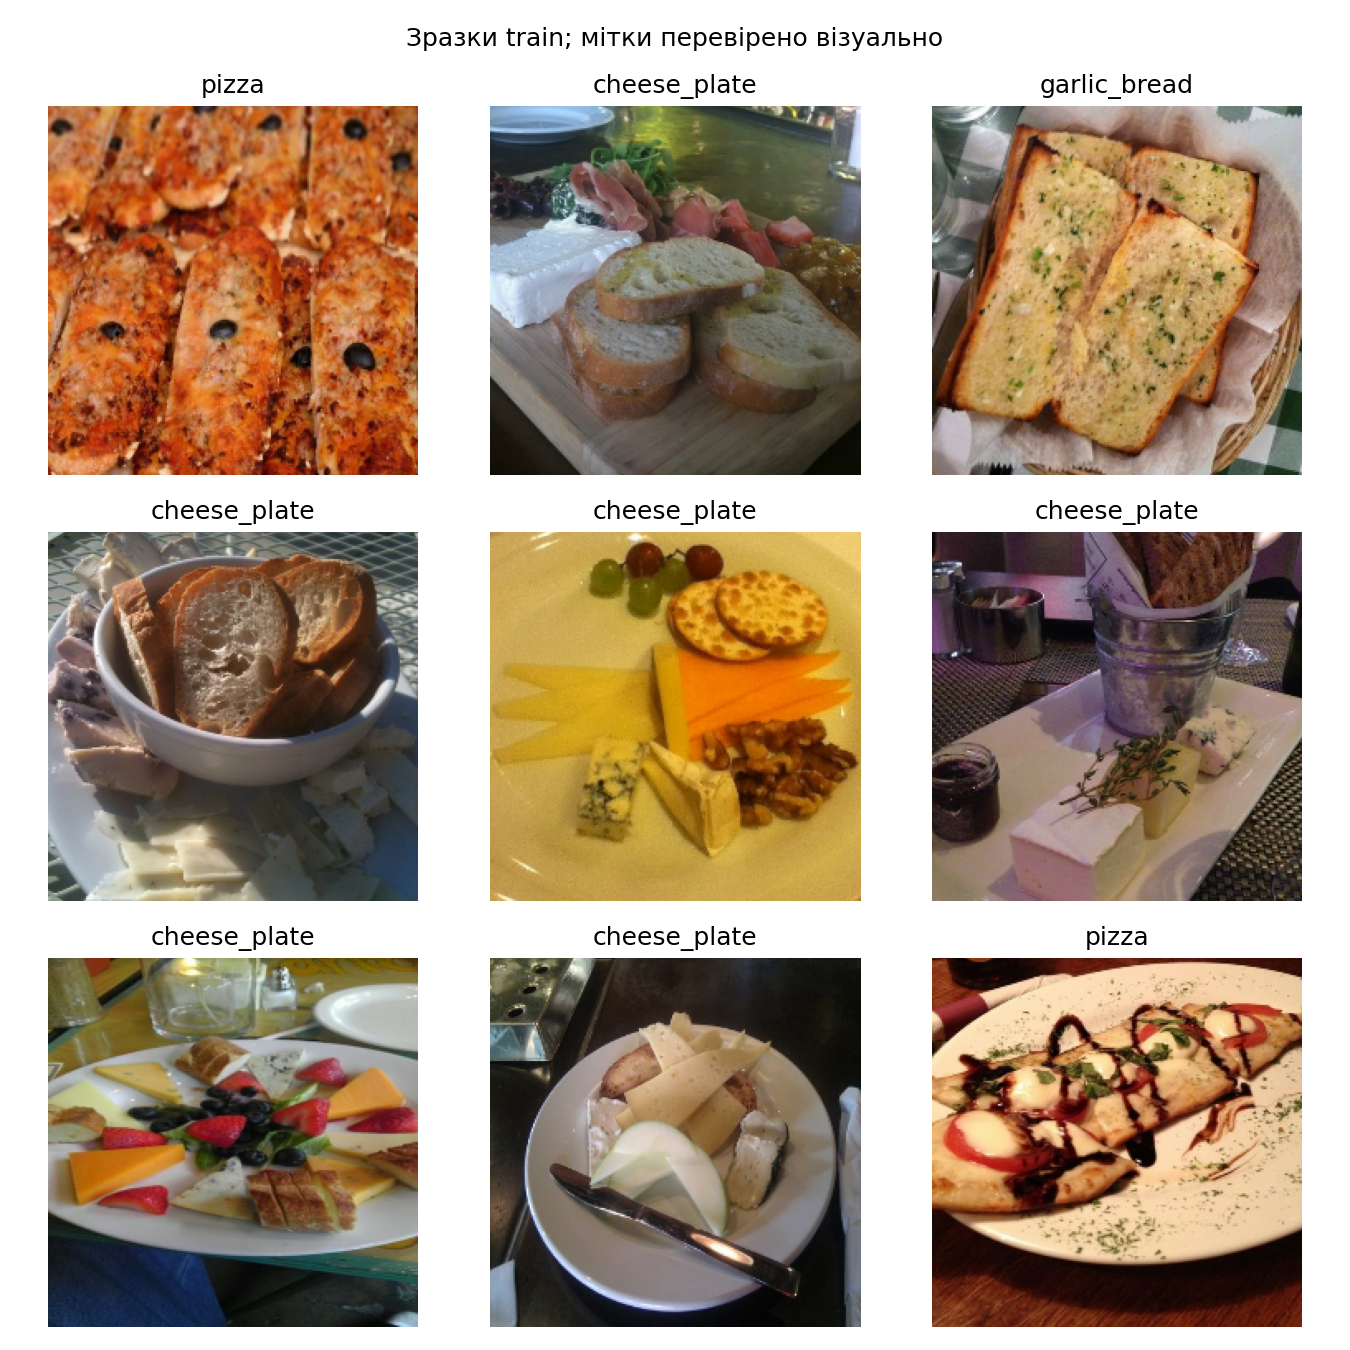

In [3]:
common = dict(image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, label_mode="int")
train_raw = keras.utils.image_dataset_from_directory(
    DATA_DIR / "train", class_names=class_names, shuffle=True, seed=SEED, **common)
val_raw = keras.utils.image_dataset_from_directory(
    DATA_DIR / "val", class_names=class_names, shuffle=False, **common)
test_raw = keras.utils.image_dataset_from_directory(
    DATA_DIR / "test", class_names=class_names, shuffle=False, **common)
assert train_raw.class_names == val_raw.class_names == test_raw.class_names == class_names
train_ds = train_raw.prefetch(tf.data.AUTOTUNE)
val_ds = val_raw.prefetch(tf.data.AUTOTUNE)
test_ds = test_raw.prefetch(tf.data.AUTOTUNE)
images, labels = next(iter(train_ds))
print("Порядок класів:", class_names)
print("Пакет:", images.shape, images.dtype, "пікселі:",
      float(tf.reduce_min(images)), float(tf.reduce_max(images)))
assert images.shape[1:] == (224, 224, 3)
assert 0 <= float(tf.reduce_min(images)) and float(tf.reduce_max(images)) <= 255
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for ax, image, label in zip(axes.flat, images[:9], labels[:9]):
    ax.imshow(np.asarray(image).astype("uint8"))
    ax.set_title(class_names[int(label)])
    ax.axis("off")
fig.suptitle("Зразки train; мітки перевірено візуально")
fig.tight_layout()
fig.savefig(OUT / "data_samples.png", dpi=150)
plt.close(fig)
display(NotebookImage(filename=str(OUT / "data_samples.png")))

## 4. Модель EfficientNetB0

`include_top=False` дає карту ознак `(7, 7, 1280)` для входу 224×224; GlobalAveragePooling2D перетворює її на вектор із 1280 ознак. На першому етапі навчається тільки Dense-голова. Аугментація й Dropout не мають навчуваних ваг.

In [4]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, seed=SEED + 1),
], name="augmentation")
base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(224, 224, 3))
base_model.trainable = False
inputs = keras.Input(shape=(224, 224, 3))
x = augmentation(inputs)
x = base_model(x, training=False)  # BatchNorm зберігає статистики ImageNet
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = keras.Model(inputs, outputs)

def trainable_count(m):
    return int(sum(np.prod(v.shape) for v in m.trainable_weights))

def compile_model(m, learning_rate):
    m.compile(optimizer=keras.optimizers.Adam(learning_rate),
              loss=keras.losses.SparseCategoricalCrossentropy(),
              metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")])

compile_model(model, 1e-3)
head_params = trainable_count(model)
assert not base_model.trainable_weights
assert head_params == 1280 * len(class_names) + len(class_names)
model.summary(show_trainable=True)
print("Навчуваних параметрів голови:", head_params)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1 (InputLayer)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ efficientnetb0 (Functional) │ (None, 7, 7, 1280)    │  4,049,571 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense (Dense)               │ (None, 3)             │      3,843 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Навчуваних параметрів голови: 3843


## 5. Feature extraction

Навчаємо нову голову з фіксованою базою, відстежуємо `val_loss`, зберігаємо найкращий checkpoint і повертаємо його ваги перед fine-tuning.

In [5]:
def callbacks(stage):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                      restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(str(OUT / f"{stage}.keras"),
                                        monitor="val_loss", save_best_only=True),
    ]

history_head = model.fit(train_ds, validation_data=val_ds,
                         epochs=HEAD_EPOCHS, callbacks=callbacks("feature_extraction"), verbose=2)
head_model = keras.models.load_model(OUT / "feature_extraction.keras")
head_val = head_model.evaluate(val_ds, return_dict=True, verbose=0)
model.set_weights(head_model.get_weights())
del head_model
print("Feature extraction:", head_val,
      "епох:", len(history_head.history["loss"]))

Epoch 1/10


57/57 - 69s - 1s/step - accuracy: 0.8228 - loss: 0.4886 - val_accuracy: 0.8956 - val_loss: 0.2911


Epoch 2/10


57/57 - 62s - 1s/step - accuracy: 0.9256 - loss: 0.2323 - val_accuracy: 0.9200 - val_loss: 0.2349


Epoch 3/10


57/57 - 66s - 1s/step - accuracy: 0.9400 - loss: 0.1954 - val_accuracy: 0.9200 - val_loss: 0.2119


... (11 outputs left out)

57/57 - 68s - 1s/step - accuracy: 0.9606 - loss: 0.1255 - val_accuracy: 0.9356 - val_loss: 0.1773


Epoch 10/10


57/57 - 70s - 1s/step - accuracy: 0.9650 - loss: 0.1138 - val_accuracy: 0.9333 - val_loss: 0.1744


Feature extraction: {'accuracy': 0.9333333373069763, 'loss': 0.17443692684173584} епох: 10


## 6. Fine-tuning верхніх блоків

Розморожуємо `block7*` і `top_*`, але залишаємо BatchNormalization замороженим. `base_model(x, training=False)` зберігає його режим інференсу; градієнти для дозволених згорток проходять. Після зміни `trainable` компілюємо модель повторно з новим оптимізатором і меншим LR.

In [6]:
base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = layer.name.startswith(("block7", "top_"))
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
unfrozen_layers = [layer.name for layer in base_model.layers if layer.trainable_weights]
assert unfrozen_layers and all(not isinstance(layer, layers.BatchNormalization)
                               for layer in base_model.layers if layer.trainable)
fine_params = trainable_count(model)
assert fine_params > head_params
print("Розморожені шари:", unfrozen_layers)
print("Навчуваних параметрів:", fine_params)
compile_model(model, 1e-5)
history_fine = model.fit(train_ds, validation_data=val_ds,
                         epochs=FINE_EPOCHS, callbacks=callbacks("fine_tuning"), verbose=2)
fine_model = keras.models.load_model(OUT / "fine_tuning.keras")
fine_val = fine_model.evaluate(val_ds, return_dict=True, verbose=0)
del fine_model
print("Fine-tuning:", fine_val,
      "епох:", len(history_fine.history["loss"]))

Розморожені шари: ['block7a_expand_conv', 'block7a_dwconv', 'block7a_se_reduce', 'block7a_se_expand', 'block7a_project_conv', 'top_conv']
Навчуваних параметрів: 1125427
Epoch 1/10


57/57 - 80s - 1s/step - accuracy: 0.9628 - loss: 0.1134 - val_accuracy: 0.9333 - val_loss: 0.1721


Epoch 2/10


57/57 - 74s - 1s/step - accuracy: 0.9606 - loss: 0.1201 - val_accuracy: 0.9333 - val_loss: 0.1713


Epoch 3/10


57/57 - 76s - 1s/step - accuracy: 0.9639 - loss: 0.1082 - val_accuracy: 0.9333 - val_loss: 0.1704


... (11 outputs left out)

57/57 - 72s - 1s/step - accuracy: 0.9700 - loss: 0.0863 - val_accuracy: 0.9356 - val_loss: 0.1633


Epoch 10/10


57/57 - 75s - 1s/step - accuracy: 0.9711 - loss: 0.0870 - val_accuracy: 0.9333 - val_loss: 0.1629


Fine-tuning: {'accuracy': 0.9333333373069763, 'loss': 0.16287507116794586} епох: 10


## 7. Порівняння за validation і вибір checkpoint

Критерій задано до перегляду test: менша validation loss. За рівності залишаємо простішу модель після першого етапу. Validation accuracy — додаткова характеристика.

In [7]:
comparison = [
    {"stage": "feature_extraction", "unfrozen": "лише голова", "lr": 1e-3,
     "params": head_params, "epochs": len(history_head.history["loss"]), **head_val},
    {"stage": "fine_tuning", "unfrozen": "block7*, top_* (без BatchNorm)",
     "lr": 1e-5, "params": fine_params,
     "epochs": len(history_fine.history["loss"]), **fine_val},
]
print("Етап | Розморожені блоки | LR | Параметри | Епохи | Val loss | Val accuracy")
for row in comparison:
    print(f'{row["stage"]} | {row["unfrozen"]} | {row["lr"]:.0e} | '
          f'{row["params"]} | {row["epochs"]} | {row["loss"]:.4f} | {row["accuracy"]:.4f}')
selected_stage = "fine_tuning" if fine_val["loss"] < head_val["loss"] else "feature_extraction"
best_model = keras.models.load_model(OUT / f"{selected_stage}.keras")
print("Обраний checkpoint:", selected_stage)

Етап | Розморожені блоки | LR | Параметри | Епохи | Val loss | Val accuracy
feature_extraction | лише голова | 1e-03 | 3843 | 10 | 0.1744 | 0.9333
fine_tuning | block7*, top_* (без BatchNorm) | 1e-05 | 1125427 | 10 | 0.1629 | 0.9333


Обраний checkpoint: fine_tuning


## 8. Незалежне підсумкове оцінювання

Лише тепер використовуємо test. Після цього кроку гіперпараметри не підбираємо за його результатами. Порівняння з Lab9 змістовне, бо набір, класи й поділ ідентичні; архітектура та розмір входу відрізняються.

In [8]:
test_metrics = best_model.evaluate(test_ds, return_dict=True, verbose=0)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
probabilities = best_model.predict(test_ds, verbose=0)
y_pred = probabilities.argmax(axis=1)
assert len(y_true) == len(y_pred) == len(test_raw.file_paths) == 750
macro_f1 = float(f1_score(y_true, y_pred, average="macro"))
report = classification_report(y_true, y_pred, labels=np.arange(len(class_names)),
                               target_names=class_names, digits=3, zero_division=0)
print("Test:", test_metrics, "macro-F1:", macro_f1)
print(report)
print("Lab9: test accuracy 0.7507, macro-F1 0.7493 (той самий поділ).")

Test: {'accuracy': 0.9626666903495789, 'loss': 0.10736453533172607} macro-F1: 0.9626321830853367
              precision    recall  f1-score   support

cheese_plate      0.976     0.964     0.970       250
garlic_bread      0.955     0.944     0.950       250
       pizza      0.957     0.980     0.968       250

    accuracy                          0.963       750
   macro avg      0.963     0.963     0.963       750
weighted avg      0.963     0.963     0.963       750

Lab9: test accuracy 0.7507, macro-F1 0.7493 (той самий поділ).


## 9. Криві, матриця помилок і помилкові прогнози

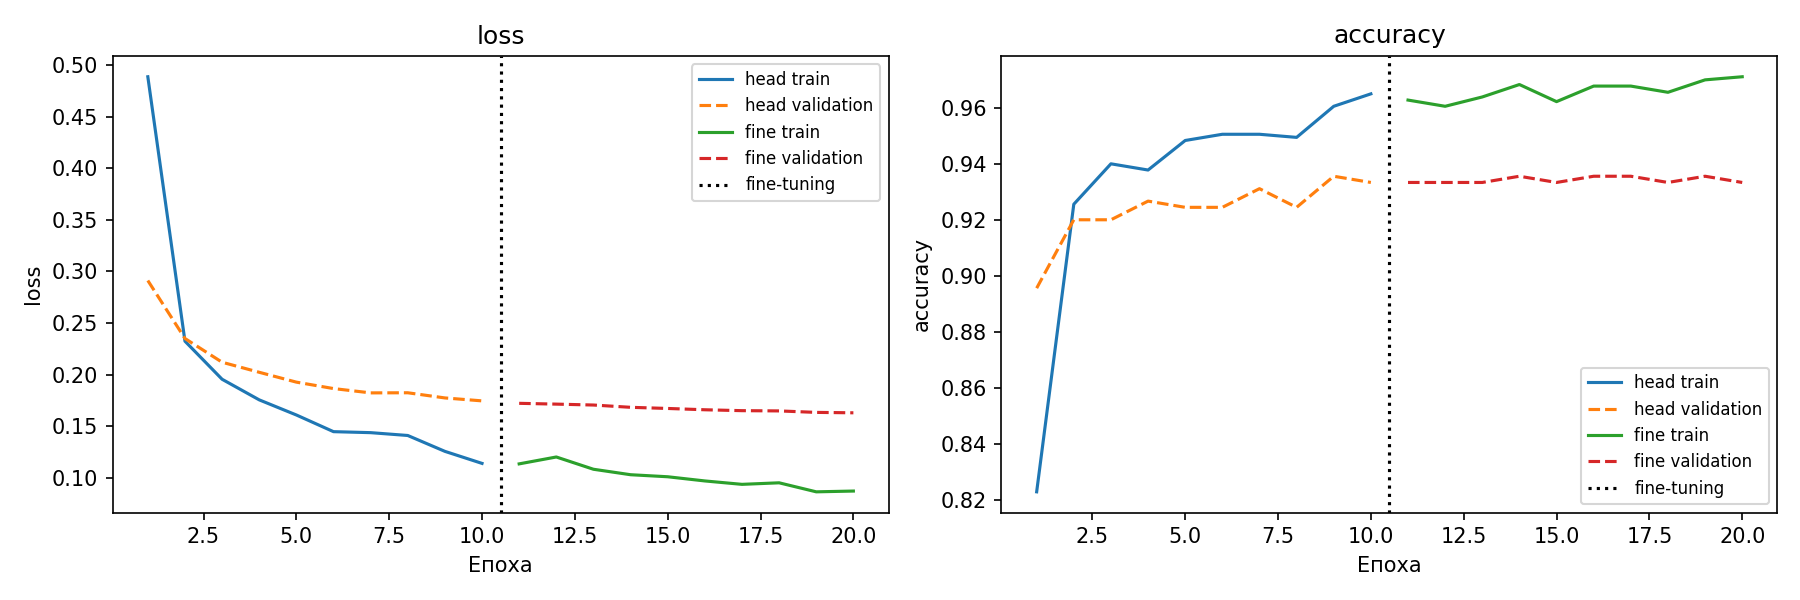

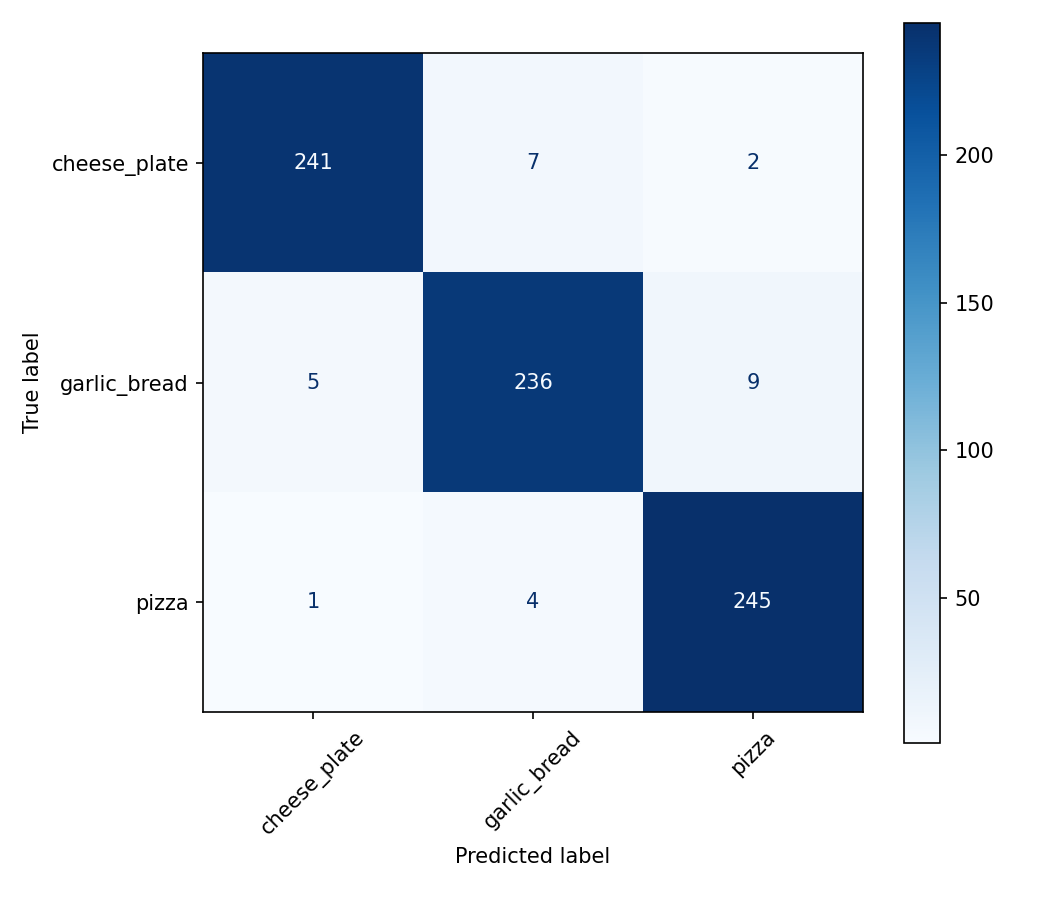

In [9]:
head_len = len(history_head.history["loss"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ("loss", "accuracy")):
    for stage, history in (("head", history_head), ("fine", history_fine)):
        offset = 0 if stage == "head" else head_len
        epochs = np.arange(1, len(history.history[metric]) + 1) + offset
        ax.plot(epochs, history.history[metric], label=f"{stage} train")
        ax.plot(epochs, history.history[f"val_{metric}"], linestyle="--",
                label=f"{stage} validation")
    ax.axvline(head_len + 0.5, color="black", linestyle=":", label="fine-tuning")
    ax.set(xlabel="Епоха", ylabel=metric, title=metric)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "training_curves.png", dpi=150)
plt.close(fig)
display(NotebookImage(filename=str(OUT / "training_curves.png")))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred,
    labels=np.arange(len(class_names)), display_labels=class_names,
    xticks_rotation=45, cmap="Blues", ax=ax)
fig.tight_layout()
fig.savefig(OUT / "confusion_matrix.png", dpi=150)
plt.close(fig)
display(NotebookImage(filename=str(OUT / "confusion_matrix.png")))

Помилкових прогнозів: 28


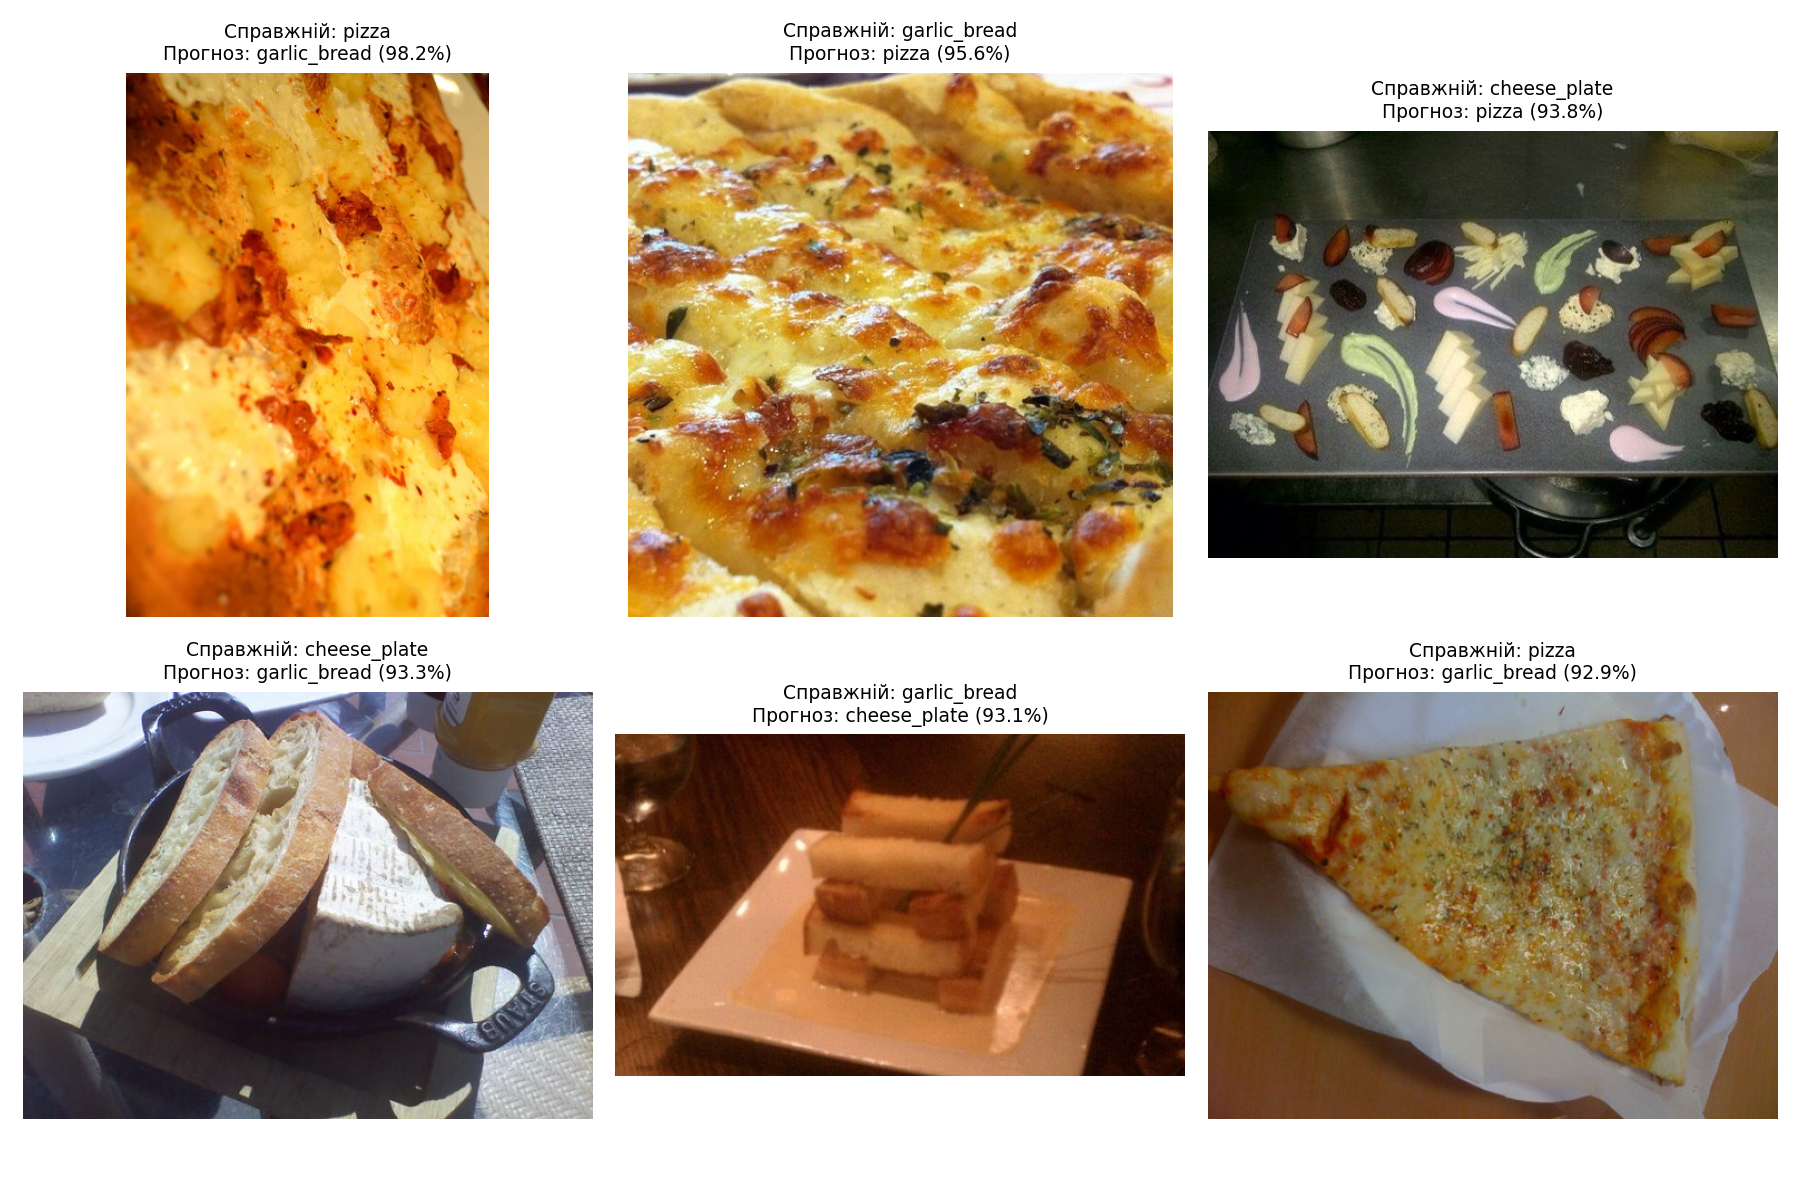

In [10]:
mistakes = np.flatnonzero(y_true != y_pred)
print("Помилкових прогнозів:", len(mistakes))
if len(mistakes):
    # Показуємо найбільш упевнені помилки, щоб бачити ризик хибної впевненості.
    chosen = sorted(mistakes, key=lambda i: probabilities[i, y_pred[i]], reverse=True)[:6]
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for ax, i in zip(axes.flat, chosen):
        with Image.open(test_raw.file_paths[i]) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(f"Справжній: {class_names[y_true[i]]}\n"
                     f"Прогноз: {class_names[y_pred[i]]} "
                     f"({probabilities[i, y_pred[i]]:.1%})", fontsize=9)
        ax.axis("off")
    for ax in axes.flat[len(chosen):]:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(OUT / "errors.png", dpi=150)
    plt.close(fig)
    display(NotebookImage(filename=str(OUT / "errors.png")))
else:
    print("Помилок немає.")

## 10. Збереження моделі, метаданих і звіту

У звіті числові висновки формуються з фактичних результатів. Softmax-оцінка прогнозованого класу не гарантує правильності. Обмеження: одна фіксована вибірка і seed, можливий шум міток Food-101, а точні хеші не виявляють майже однакових фото.

In [11]:
best_model.save(OUT / "selected_model.keras")
confusion = tf.math.confusion_matrix(y_true, y_pred, num_classes=len(class_names)).numpy()
pairs = [(int(confusion[i, j]), class_names[i], class_names[j])
         for i in range(len(class_names)) for j in range(len(class_names)) if i != j]
pairs.sort(reverse=True)
most_confused = pairs[0]
next_change = "спробувати розморозити також block6* за того самого LR та validation-протоколу"
metadata = {
    "python": sys.version.split()[0], "tensorflow": tf.__version__, "keras": keras.__version__,
    "seed": SEED, "variant": 17, "source": "Food-101 / Lab9 manifest.json",
    "class_indices": [16, 46, 76], "class_names": class_names,
    "split_counts_per_class": expected_per_class, "image_size": list(IMAGE_SIZE),
    "pixel_range": [0, 255], "backbone": "EfficientNetB0", "weights": "imagenet",
    "unfrozen_layers": unfrozen_layers, "selected_stage": selected_stage,
    "comparison": comparison, "test_metrics": test_metrics, "macro_f1": macro_f1,
    "most_confused": {"count": most_confused[0], "true": most_confused[1], "predicted": most_confused[2]},
}
(OUT / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
rows_md = "\n".join(
    f'| {r["stage"]} | {r["unfrozen"]} | {r["lr"]:.0e} | {r["params"]} | {r["epochs"]} | {r["loss"]:.4f} | {r["accuracy"]:.4f} |'
    for r in comparison)
result = "зменшило validation loss" if selected_stage == "fine_tuning" else "не зменшило validation loss"
head_best_epoch = int(np.argmin(history_head.history["val_loss"])) + 1
fine_best_epoch = int(np.argmin(history_fine.history["val_loss"])) + 1
curve_summary = (f"Найнижча validation loss на епосі {head_best_epoch} першого етапу "
                 f"та {fine_best_epoch} другого. Train loss загалом зменшувалася, "
                 f"validation accuracy після початкового зростання трималася близько {fine_val['accuracy']:.3f}. "
                 "Стійкого зростання validation loss не спостерігається; "
                 "ліміт епох міг зупинити подальше поліпшення.")
report_md = f"""# Звіт до лабораторної роботи № 10 — варіант 17

## Мета й дані
Трансферне навчання EfficientNetB0 на Food-101; Python {sys.version.split()[0]}, TensorFlow {tf.__version__}, Keras {keras.__version__}. Класи: {", ".join(class_names)} (індекси 16, 46, 76). На кожен клас: 600 train, 150 validation, 250 test. Застосовано незмінний manifest Lab9 (seed {SEED}); точних SHA-256-дублікатів та пошкоджених JPEG не знайдено. Різні кадри одного об'єкта за ID надійно не ідентифікуються.

## Метод
RGB 224×224, пікселі [0, 255], оскільки EfficientNetB0 містить препроцесинг. Аугментація лише train: горизонтальне віддзеркалення та невеликий поворот. Feature extraction: заморожена база, GAP, Dropout 0.2, softmax-голова, Adam 1e-3. Fine-tuning: block7* і top_* без BatchNormalization, Adam 1e-5. Зупинка та checkpoints за validation loss.

## Порівняння validation
| Етап | Розморожені блоки | LR | Навчувані параметри | Епохи | Validation loss | Validation accuracy |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
{rows_md}

Обрано **{selected_stage}** за меншою validation loss (за рівності — перший етап). Часткове донавчання {result}. {curve_summary} Графіки: `training_curves.png`.

## Незалежний test
Accuracy: **{test_metrics["accuracy"]:.4f}**; macro-F1: **{macro_f1:.4f}**. У Lab9 на тому самому поділі: accuracy 0.7507, macro-F1 0.7493. Матриця помилок: `confusion_matrix.png`; приклади: `errors.png`.

Покласовий звіт:
```
{report}
```

Найбільша плутанина: **{most_confused[1]} → {most_confused[2]}**, {most_confused[0]} фото. Можливі причини: схожі інгредієнти, фон, ракурс та шумні мітки train. Висока softmax-імовірність не гарантує правильності.

## Висновок
За одним seed оцінка має варіативність. Test не використовувався для вибору моделі чи параметрів. Наступна перевірка: {next_change}; її слід виконати з того самого найкращого checkpoint першого етапу і порівняти за validation до нового незалежного test.

Джерело: https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/ . Права на фото належать авторам; їх не поширюємо в репозиторії. Код: https://github.com/StanisLaw194/data-mining .
"""
(OUT / "report.md").write_text(report_md, encoding="utf-8")
print(report_md)

# Звіт до лабораторної роботи № 10 — варіант 17

## Мета й дані
Трансферне навчання EfficientNetB0 на Food-101; Python 3.9.6, TensorFlow 2.16.2, Keras 3.10.0. Класи: cheese_plate, garlic_bread, pizza (індекси 16, 46, 76). На кожен клас: 600 train, 150 validation, 250 test. Застосовано незмінний manifest Lab9 (seed 42); точних SHA-256-дублікатів та пошкоджених JPEG не знайдено. Різні кадри одного об'єкта за ID надійно не ідентифікуються.

## Метод
RGB 224×224, пікселі [0, 255], оскільки EfficientNetB0 містить препроцесинг. Аугментація лише train: горизонтальне віддзеркалення та невеликий поворот. Feature extraction: заморожена база, GAP, Dropout 0.2, softmax-голова, Adam 1e-3. Fine-tuning: block7* і top_* без BatchNormalization, Adam 1e-5. Зупинка та checkpoints за validation loss.

## Порівняння validation
| Етап | Розморожені блоки | LR | Навчувані параметри | Епохи | Validation loss | Validation accuracy |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| feature_extraction | лише г

## Відповіді на контрольні запитання

1. **Ваги:** під час feature extraction оновлюється тільки Dense-голова; під час fine-tuning — голова й дозволені верхні згортки бази.
2. **Пікселі:** EfficientNetB0 в Keras уже містить потрібний препроцесинг і очікує [0, 255].
3. **Карта і GAP:** карта `(7, 7, 1280)` зберігає просторове розташування ознак; GAP усереднює кожен канал до вектора `(1280,)`.
4. **`trainable=False` і `training=False`:** перше забороняє оновлення ваг, друге задає режим прямого проходу, зокрема для BatchNormalization і Dropout.
5. **Повторна компіляція:** оновлює набір навчуваних ваг у графі оптимізатора та створює оптимізатор із новим LR.
6. **Test:** підбір за test перетворює його на validation і завищує оцінку узагальнення.
7. **Погіршення fine-tuning:** залишаємо checkpoint першого етапу, якщо його validation loss нижча.

Додатковий експеримент зі зміною одного параметра наведено як наступний крок у звіті; він не входить до основного завдання методички.